# Frozen-model EDA and improvement hypotheses

The official Qwen3-4B submission scored **0.97025**. All new error analysis below uses
the 5,746 development examples; the previous confirmation result is not reused to
select improvements. Intervals resample entire prompt groups. Slice comparisons are
exploratory and are not corrected for multiple comparisons or prior model selection.


In [1]:
from pathlib import Path
import json,sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
REPO=next(p for p in [Path.cwd(),Path.cwd().parent,Path.home()/'prj/llm_classification_finetuning'] if (p/'results/eda_002').exists())
sys.path.insert(0,str(REPO/'src'))
from arena.data import ROOT
R=REPO/'results/eda_002'
FIG=ROOT/'reports/eda_002';FIG.mkdir(parents=True,exist_ok=True)
read=lambda name:json.loads((R/name).read_text())
dataset=read('dataset_summary.json');schema=read('schema.json')
plt.rcParams.update({'figure.figsize':(10,4),'axes.spines.top':False,'axes.spines.right':False})
def finish(name):
    plt.tight_layout();plt.savefig(FIG/(name+'.svg'));plt.show()

model=read('model_summary.json')
slices=pd.DataFrame(read('model_slices.json'))
diagnostic=read('inference_diagnostic.json')
post=read('postprocessing_diagnostics.json')


In [2]:
display(pd.DataFrame({k:model[k] for k in ['frozen_calibrated','raw_swap_average','prior','majority','uniform']}).T)
print('Development log-loss group-bootstrap interval:',model['log_loss_95_group_bootstrap'])
print('Development accuracy group-bootstrap interval:',model['accuracy_95_group_bootstrap'])


,rows,log_loss,accuracy,balanced_accuracy,macro_f1,brier
frozen_calibrated,5746.0,0.968825,0.527323,0.524737,0.524611,0.577675
raw_swap_average,5746.0,0.977384,0.527323,0.524737,0.524611,0.583194
prior,5746.0,1.097216,0.349112,0.333333,0.172515,0.665747
majority,5746.0,23.460366,0.349112,0.333333,0.172515,1.301775
uniform,5746.0,1.098612,0.349112,0.333333,0.172515,0.666667


Development log-loss group-bootstrap interval: [0.9541697135865717, 0.9831916095372591]
Development accuracy group-bootstrap interval: [0.5155981381979913, 0.5408130682649768]


## Training duration and checkpoint selection

Training stopped for budget at step 877 / 0.61 epochs. The selected checkpoint was
800. Late selection loss was fairly flat, so incomplete training alone does not prove
large remaining gains. Logged training minibatches use augmentation and dropout;
their loss is not a clean train-versus-validation generalization-gap measurement.


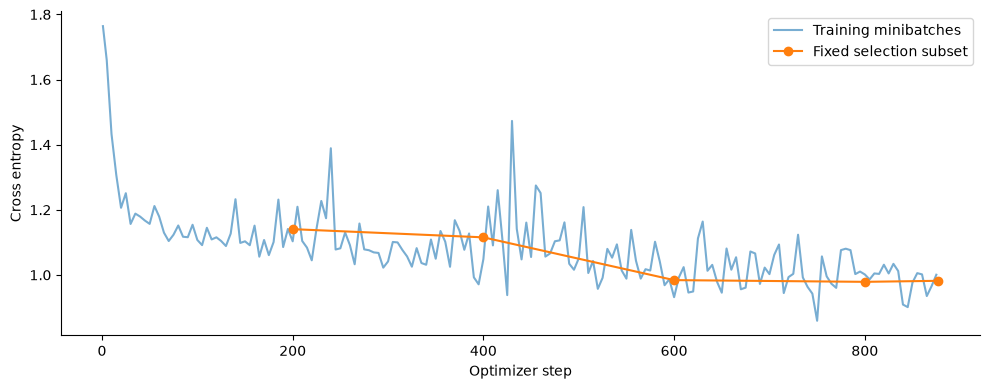

,step,epoch,eval_log_loss,eval_accuracy
41,200,0.139155,1.140517,0.438477
82,400,0.278309,1.115365,0.412109
123,600,0.417464,0.983990,0.503906
164,800,0.556619,0.978704,0.513672
180,877,0.610193,0.981858,0.524414


In [3]:
history=pd.read_json(REPO/'results/attempt_002/qwen4b1024/training_progress.jsonl',lines=True)
training=history.dropna(subset=['loss']);validation=history.dropna(subset=['eval_log_loss'])
plt.plot(training.step,training.loss,alpha=.6,label='Training minibatches')
plt.plot(validation.step,validation.eval_log_loss,'o-',label='Fixed selection subset')
plt.xlabel('Optimizer step');plt.ylabel('Cross entropy');plt.legend();finish('training_curve')
display(validation[['step','epoch','eval_log_loss','eval_accuracy']])


## Class discrimination and calibration

Tie recall and AUC are lower than for A/B winners. Predicted tie frequency is close
to its prevalence, so this is not simply a minority-class problem. Temperature
scaling already repairs much of the overall underconfidence; this improvement is
included in the official result and cannot be counted again as a future gain.


,class,rows,prevalence,mean_predicted_probability,prediction_fraction,recall,precision,log_loss,loss_share,one_vs_rest_auc
0,winner_model_a,2006,0.3491,0.3326,0.3482,0.5598,0.5612,0.9484,0.3418,0.7373
1,winner_model_b,1965,0.3420,0.3322,0.3481,0.5603,0.5505,0.9604,0.3390,0.7283
2,winner_tie,1775,0.3089,0.3352,0.3037,0.4541,0.4619,1.0012,0.3192,0.6676


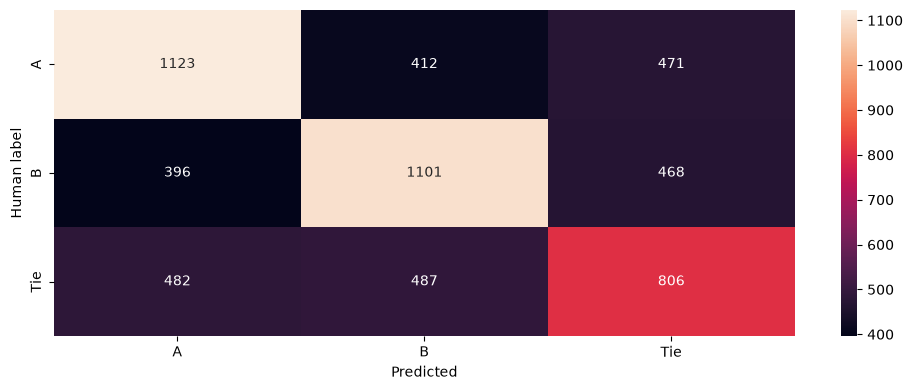

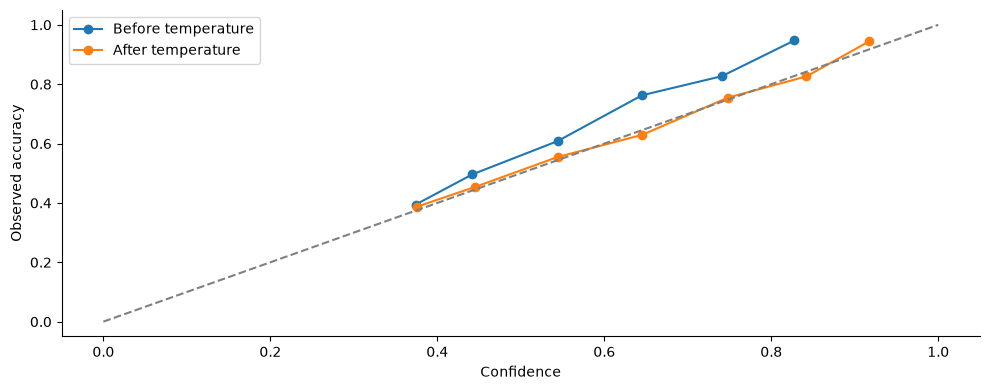

ECE before/after: 0.05365673651431275 0.010736891060048555
Calibration log-loss gain: 0.008558255315313349 [0.0050392686530872635, 0.011997402355153999]


In [4]:
display(pd.DataFrame(model['per_class']).round(4))
sns.heatmap(np.array(model['confusion_counts']),annot=True,fmt='d',xticklabels=['A','B','Tie'],yticklabels=['A','B','Tie'])
plt.xlabel('Predicted');plt.ylabel('Human label');finish('confusion_matrix')
for key,label in [('reliability_raw','Before temperature'),('reliability_calibrated','After temperature')]:
    bins=pd.DataFrame(model[key]['bins']);plt.plot(bins.confidence,bins.accuracy,'o-',label=label)
plt.plot([0,1],[0,1],'--',color='gray');plt.xlabel('Confidence');plt.ylabel('Observed accuracy');plt.legend();finish('reliability')
print('ECE before/after:',model['reliability_raw']['ece'],model['reliability_calibrated']['ece'])
print('Calibration log-loss gain:',model['calibration_gain'],model['calibration_gain_95_group_bootstrap'])


## Where errors concentrate

These overlapping groups differ in difficulty. In particular, multi-turn, code-like
and long-prompt slices often also lose context. The loss of untruncated examples is
already far above 0.8. Removing a few catastrophic examples is not a demonstrated
route to that target.


In [5]:
chosen=slices[(slices.rows>=100)&slices.feature.isin(['multi_turn','task_code','cut_1024_cap256','prompt_cut_1024_cap256','answer_embedding_cosine','language_group'])]
display(chosen[['feature','value','rows','log_loss','accuracy','tie_rate','truncation_rate','delta_ci_low','delta_ci_high']].round(4))
display(slices[slices.feature.isin(['multi_turn_x_truncation','task_code_x_truncation'])].round(4))
display(pd.DataFrame(model['loss_tail']))
display(pd.Series(model['confident_wrong']))


,feature,value,rows,log_loss,accuracy,tie_rate,truncation_rate,delta_ci_low,delta_ci_high
0,multi_turn,True,809,1.0189,0.4944,0.3127,0.6218,0.0335,0.0850
1,multi_turn,False,4937,0.9606,0.5327,0.3083,0.1315,-0.0850,-0.0335
19,language_group,ENGLISH,3649,0.9859,0.5196,0.3036,0.2924,0.0163,0.0784
20,language_group,UNKNOWN,2035,0.9373,0.5455,0.3155,0.0339,-0.0814,-0.0188
43,cut_1024_cap256,True,1152,1.0268,0.4878,0.3021,1.0000,0.0473,0.0987
44,cut_1024_cap256,False,4594,0.9543,0.5372,0.3106,0.0000,-0.0987,-0.0473
45,prompt_cut_1024_cap256,False,5328,0.9632,0.5317,0.3071,0.1378,-0.1239,-0.0369
46,prompt_cut_1024_cap256,True,418,1.0410,0.4713,0.3325,1.0000,0.0369,0.1239
61,task_code,False,5197,0.9636,0.5297,0.3088,0.1784,-0.0948,-0.0140
62,task_code,True,549,1.0181,0.5046,0.3097,0.4098,0.0140,0.0948


,feature,value,rows,fraction,log_loss,log_loss_ci_low,log_loss_ci_high,accuracy,tie_rate,truncation_rate,loss_delta_vs_rest,delta_ci_low,delta_ci_high
113,multi_turn_x_truncation,False; cut=False,4288,0.7463,0.9517,0.9333,0.9700,0.5389,0.3097,0.0,-0.0676,-0.0926,-0.0433
114,multi_turn_x_truncation,False; cut=True,649,0.1129,1.0197,0.9907,1.0449,0.4915,0.2989,1.0,0.0574,0.0277,0.0905
115,multi_turn_x_truncation,True; cut=False,306,0.0533,0.9909,0.9531,1.0292,0.5131,0.3235,0.0,0.0234,-0.0187,0.0674
116,multi_turn_x_truncation,True; cut=True,503,0.0875,1.0360,1.0101,1.0634,0.4831,0.3062,1.0,0.0736,0.0441,0.1052
117,task_code_x_truncation,False; cut=False,4270,0.7431,0.9509,0.9339,0.9688,0.5377,0.3096,0.0,-0.0699,-0.0941,-0.0436
118,task_code_x_truncation,False; cut=True,927,0.1613,1.0223,1.0018,1.0453,0.4930,0.3053,1.0,0.0638,0.0369,0.0921
119,task_code_x_truncation,True; cut=False,324,0.0564,0.9992,0.9504,1.0519,0.5309,0.3241,0.0,0.0322,-0.0184,0.0879
120,task_code_x_truncation,True; cut=True,225,0.0392,1.0454,0.9967,1.0933,0.4667,0.2889,1.0,0.0797,0.0303,0.1297


,top_fraction,rows,loss_share,min_loss,tie_fraction,truncated_fraction
0,0.01,58,0.028403,2.386051,0.120690,0.051724
1,0.05,288,0.112170,1.795981,0.211806,0.083333
2,0.10,575,0.197772,1.552450,0.248696,0.095652
3,0.20,1150,0.345025,1.324134,0.279130,0.167826


rows          51.000000
fraction       0.008876
loss_share     0.023011
dtype: float64

## Controlled inference diagnostics: answer order and context

Before inference, 512 development rows were sampled uniformly with seed 20261107,
without selecting on errors. Original and swapped predictions were recomputed with
the frozen adapter. Only changed inputs needed additional 2,048-token inference.
The training tokenizer, adapter hash and existing temperature were retained.

**The 512-row subset is easier than the full development set. Its absolute scores
are not new Kaggle estimates.** The paired changes and their intervals are the
relevant measurements. Swap averaging is already deployed; its observed gain is
not an additional available improvement. The context test uses the existing frozen
temperature and has no independently refitted long-context calibration.


,log_loss,accuracy,balanced_accuracy,macro_f1,brier
raw_original,0.97465,0.52539,0.53024,0.52269,0.58141
raw_swap_average,0.95174,0.56250,0.56095,0.55971,0.56596
calibrated_original,0.97223,0.52539,0.53024,0.52269,0.57826
calibrated_swap_average,0.93410,0.56250,0.56095,0.55971,0.55441
calibrated_2048,0.92946,0.54883,0.54769,0.54566,0.55195


rows                                                                     512
context_changed_rows                                                     107
order_argmax_disagreement_fraction                                  0.380859
order_flip_fraction_95_group_bootstrap                  [0.339135, 0.425455]
second_position_mean_probability_advantage                          0.083291
second_position_advantage_95_group_bootstrap              [0.07505, 0.09141]
context_2048_gain                                                   0.004641
context_2048_gain_95_group_bootstrap                   [-0.001139, 0.010718]
context_2048_accuracy_change                                       -0.013672
baseline_reload_max_absolute_probability_difference                 0.001456
inference_seconds                                                 504.489942
peak_gpu_bytes                                                    6526629376
dtype: object

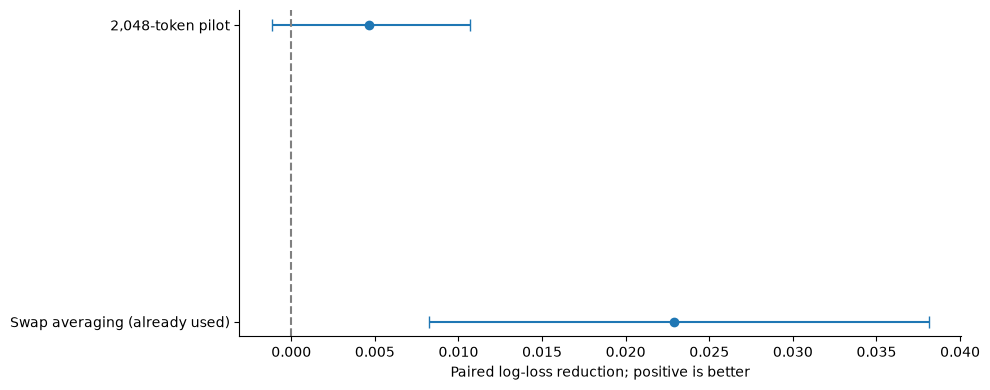

In [6]:
display(pd.DataFrame({k:diagnostic[k] for k in ['raw_original','raw_swap_average','calibrated_original','calibrated_swap_average','calibrated_2048']}).T.round(5))
display(pd.Series({k:diagnostic[k] for k in ['rows','context_changed_rows','order_argmax_disagreement_fraction','order_flip_fraction_95_group_bootstrap','second_position_mean_probability_advantage','second_position_advantage_95_group_bootstrap','context_2048_gain','context_2048_gain_95_group_bootstrap','context_2048_accuracy_change','baseline_reload_max_absolute_probability_difference','inference_seconds','peak_gpu_bytes']}))
gains=[diagnostic['raw_swap_averaging_gain'],diagnostic['context_2048_gain']]
ci=np.array([diagnostic['raw_swap_averaging_gain_95_group_bootstrap'],diagnostic['context_2048_gain_95_group_bootstrap']])
plt.errorbar(gains,[0,1],xerr=np.array([np.array(gains)-ci[:,0],ci[:,1]-np.array(gains)]),fmt='o',capsize=4)
plt.axvline(0,color='gray',ls='--');plt.yticks([0,1],['Swap averaging (already used)','2,048-token pilot'])
plt.xlabel('Paired log-loss reduction; positive is better');finish('paired_inference_gains')


## Cheap postprocessing hypotheses

Five folds cross-fit only the calibration/blend parameters on fixed development
predictions. These are not out-of-fold language models: checkpoint selection already
used part of development. A tie-specific intercept preserves A/B swap symmetry.
The structural model was trained on the same training partition as LoRA. Both
exploratory gains have intervals spanning zero, so neither is a confirmed improvement.


In [7]:
display(pd.DataFrame({k:post[k] for k in ['calibration_oof','tie_calibration_oof','structural_blend_oof','structural_base']}).T.round(5))
display(pd.DataFrame(post['folds']).round(4))
print('Tie adjustment gain:',post['tie_calibration_gain'],post['tie_calibration_gain_95_group_bootstrap'])
print('Structural blend gain:',post['blend_gain'],post['blend_gain_95_group_bootstrap'])


,rows,log_loss,accuracy,balanced_accuracy,macro_f1,brier
calibration_oof,5746.0,0.96932,0.52732,0.52474,0.52461,0.57796
tie_calibration_oof,5746.0,0.96762,0.53167,0.52608,0.52262,0.57668
structural_blend_oof,5746.0,0.96859,0.52628,0.52332,0.52294,0.57734
structural_base,5746.0,1.03375,0.47355,0.46792,0.46359,0.62069


,fold,calibration_temperature,lora_weight,blend_temperature,tie_temperature,tie_logit_bias
0,0,0.7355,0.9,0.6976,0.7381,-0.1339
1,1,0.7002,0.9,0.6640,0.7024,-0.1390
2,2,0.7120,0.9,0.6757,0.7154,-0.1203
3,3,0.7470,0.8,0.6752,0.7496,-0.1353
4,4,0.7167,0.9,0.6805,0.7194,-0.1326


Tie adjustment gain: 0.0016956676248957355 [-0.00016675082233185798, 0.0033182991526886385]
Structural blend gain: 0.0007281353648039766 [-0.000537273356802964, 0.0019911261647043753]


## Qualitative review and hypotheses

The local private gallery contains selected difficult cases with complete text.
The table below contains paraphrases only. These deliberately selected examples
illustrate failure mechanisms; they cannot estimate their population frequency.
Two factual examples have primary-source checks. Subjective votes are not relabeled.


In [8]:
display(pd.DataFrame(read('manual_case_notes.json'))[['id','theme','observation','interpretation']])
print('Private full-text gallery:',ROOT/'eda/attempt_002/private_error_gallery.html')
display(pd.DataFrame(read('hypotheses.json')))


,id,theme,observation,interpretation
0,836802513,Factuality versus polished presentation,The model strongly prefers a detailed biograph...,At least one checkable false statement in the ...
1,2771615169,Specific knowledge versus fluent denial,The model prefers an answer denying that a nam...,A short untruncated comparison can still requi...
2,2302932761,Instruction adherence and ties,A task requests exactly three sentences. One c...,A plausible both-unsatisfactory tie; explicit ...
3,2217838490,Verbosity and subjective equivalence,A general forecasting question receives a deta...,Illustrates a possible style shortcut and subj...
4,1485267511,Refusal style,Both candidates reject an insulting request. T...,Human preferences may concern concision or ton...
5,91135016,Repeated prompt with differing answers,A second comparison for the same request again...,Same prompt with different answers is not a du...
6,66663160,Both answers imperfect,A programming request asks for an outline befo...,Comparative quality requires weighing several ...
7,2106457410,Automatic task-tag false positive,A question mentioning a python concerns animal...,"Task slices are code-like lexical proxies, not..."


Private full-text gallery: /home/tarstars/database/llm_classification_finetuning/eda/attempt_002/private_error_gallery.html


,priority,hypothesis,evidence,confidence,test,success
0,1,Comparison features depend too much on answer ...,Raw winner flips in 38.1% of 512 paired-order ...,High for instability; moderate for its explana...,Compare random swapping with paired-order CE p...,Lower paired-order disagreement AND lower full...
1,2,"Subtle correctness, instruction following and ...",Tie recall 45.4% vs about 56% for A/B; tie AUC...,Moderate; selected examples do not establish f...,Review a stratified random error sample; test ...,Lower tie/near-similar-pair loss without worse...
2,3,Lost context and conversation layout contribut...,20.0% truncated; loss 1.027 vs 0.954. Multi-tu...,High for association; inconclusive for the siz...,A larger paired context ablation; test 2048 to...,Paired gain interval positive on full developm...
3,4,The six-hour stop left useful training unfinished,"Only 0.61 epochs completed, but late selection...",Unresolved,Exact full-checkpoint continuation to one epoc...,Improvement beyond the fixed step-800 baseline...
4,5,Tie probabilities need an additional class-spe...,Mean tie probability 0.335 vs prevalence 0.309...,Weak remaining gain; global temperature calibr...,Predeclare temperature + tie intercept and eva...,"Repeated paired gain, not just in-sample fitte..."
5,6,Structural features complement LoRA enough for...,"Cross-fitted postprocessor gain 0.0007, interv...",Weak,Only consider a predeclared simple blend if a ...,Gain remains after evaluation costs and indepe...
6,7,Class imbalance or a few corrupted rows explai...,Labels about 35/34/31%; no turn-count mismatch...,Not supported as a main explanation,Manual quality checks and invariants; do not a...,"An identified, reproducible data defect with m..."
7,8,Non-English data is the main weakness,Language estimates leave many short/code-heavy...,Insufficient evidence,Annotate a representative language sample and ...,Reliable language labels and a reproducible co...


## Recommended experiments

The evidence prioritizes learning a more stable and semantically useful comparison:
paired-order training/consistency or a shared utility-plus-tie architecture; more
attention to subtle correctness and explicit instruction constraints; and a controlled
continuation to test convergence. Longer/round-aware packing remains a candidate,
but the small context pilot does not establish a large gain. Class weighting,
unverified label cleaning and additional scalar calibration are weak first priorities.

Use the development set for exploratory choices. The old confirmation partition has
already been evaluated. Any subsequent evaluation must disclose this history and
must not call it a new untouched confirmation. No new model was trained or submitted
as part of this EDA.
